# INF201 Deliverable 1: Weather data from Ås

GitHub repository: https://github.com/fabianfeiler/inf201-h26-deliverable-1

In [ ]:
from pathlib import Path


import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import requests

CLIENT_ID_PATH = Path.home() / "frost_client_id.txt"


def read_client_id(path: Path = CLIENT_ID_PATH) -> str:
    """Read Frost client ID from a file outside the Git repository."""
    return path.read_text(encoding="utf-8").strip()

CLIENT_ID = read_client_id()

## Task 1: Temperature

The function for retrieving data is adapted from MET's Python example
(https://frost.met.no/python_example.html). We replaced `df.append()`,
which is removed in newer pandas, and read the client ID from a file
outside the repository.

In [ ]:
# Adapted from MET's Frost Python example: https://frost.met.no/python_example.html
ENDPOINT = "https://frost.met.no/observations/v0.jsonld"


def fetch_frost(parameters: dict[str, str], client_id: str = CLIENT_ID) -> pd.DataFrame:
    """Fetch observations from Frost and return them as a DataFrame."""
    r = requests.get(ENDPOINT, parameters, auth=(client_id, ""), timeout=30)
    if r.status_code != 200:
        error = r.json()["error"]
        raise RuntimeError(f"Frost {r.status_code}: {error['message']} ({error['reason']})")
    rows = [
        {"referenceTime": item["referenceTime"], **obs}
        for item in r.json()["data"]
        for obs in item["observations"]
    ]
    df = pd.DataFrame(rows)
    df["referenceTime"] = pd.to_datetime(df["referenceTime"])
    return df[["referenceTime", "elementId", "value", "unit", "timeOffset"]]

The task suggests `referencetime = 2025-01-01/2025-12-31`, but Frost treats
the end date as exclusive, which returned only 364 days (31 December was
missing). We therefore use `2025-01-01/2026-01-01` to get the full year.

In [ ]:
TEMP_PARAMETERS = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
    "levels": "default",
}

temp_2025 = fetch_frost(TEMP_PARAMETERS)

print(f"Rows: {len(temp_2025)}")
print(f"Duplicate dates: {temp_2025['referenceTime'].duplicated().sum()}")
temp_2025.head()

Rows: 365
Duplicate dates: 0


,referenceTime,elementId,value,unit,timeOffset
0,2025-01-01 00:00:00+00:00,mean(air_temperature P1D),-5.2,degC,PT0H
1,2025-01-02 00:00:00+00:00,mean(air_temperature P1D),-11.5,degC,PT0H
2,2025-01-03 00:00:00+00:00,mean(air_temperature P1D),-8.9,degC,PT0H
3,2025-01-04 00:00:00+00:00,mean(air_temperature P1D),-15.5,degC,PT0H
4,2025-01-05 00:00:00+00:00,mean(air_temperature P1D),-12.5,degC,PT0H


In [ ]:
all_days = pd.date_range("2025-01-01", "2025-12-31", tz="UTC")
missing = all_days.difference(temp_2025["referenceTime"])
print(missing)

DatetimeIndex([], dtype='datetime64[us, UTC]', freq='D')


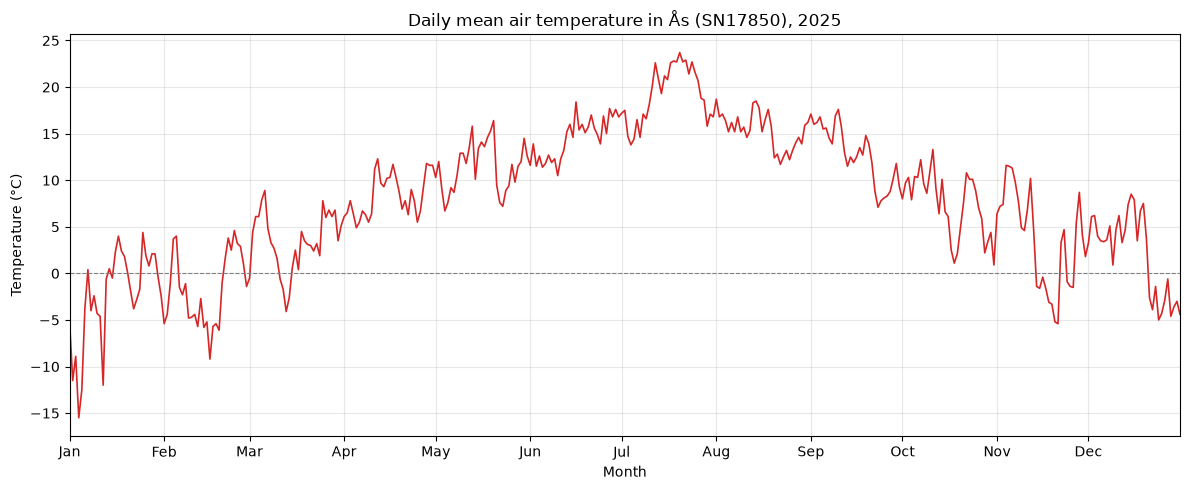

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_2025["referenceTime"], temp_2025["value"], color="tab:red", linewidth=1.2)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title("Daily mean air temperature in Ås (SN17850), 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025["referenceTime"].min(), temp_2025["referenceTime"].max())
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()